#  Humain ou IA ? Détecter les textes générés par intelligence artificielle

Avec ChatGPT et les autres IA génératives, il devient difficile de savoir si un texte a été écrit par une personne ou par une machine. C'est un vrai problème pour l'**intégrité académique** (devoirs, mémoires, articles scientifiques) et pour la **fiabilité de l'information** en ligne.

Dans ce projet, je construis **mon propre modèle**, sans aucun modèle pré-entraîné, qui lit un texte en anglais et prédit s'il a été **écrit par un humain** ou **généré par une IA**. Pour qu'il reconnaisse aussi les IA récentes, je l'entraîne sur des textes produits par **plusieurs générations d'IA** (dont GPT-4 et des versions plus récentes, Qwen, Mistral, LLaMA) et dans **plusieurs domaines**.

Je reprends la même démarche que le notebook d'analyse de sentiment (IMDB) :

1. Charger et préparer les données
2. Transformer le texte en nombres avec `TextVectorization`
3. Entraîner le même réseau de neurones (Embedding, Dropout, GlobalAveragePooling1D, Dense)
4. Évaluer le modèle

Et j'ajoute trois choses :

5. **Les mots qui trahissent l'IA** : je regarde ce que le modèle a appris
6. **Un stress test** : je le teste sur des textes qu'il n'a jamais vus, pour trouver ses limites
7. **Une interface** pour l'utiliser simplement

##  Importation des bibliothèques

J'utilise TensorFlow pour le modèle, `datasets` pour télécharger les textes, pandas et scikit-learn pour manipuler les données et analyser les résultats, et **Gradio** pour l'interface.

In [1]:
# J'installe les bibliothèques qui ne sont pas fournies par défaut
# (%pip installe dans l'environnement Python du notebook, celui choisi comme noyau dans VS Code)
%pip install -U datasets pandas scikit-learn gradio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Outils de base
import matplotlib.pyplot as plt   # pour tracer les courbes
import re                         # pour les expressions régulières
import string                     # pour récupérer la liste de la ponctuation
import numpy as np
import pandas as pd

# TensorFlow et Keras : le cœur du projet
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import losses

# La bibliothèque qui me permet de télécharger le jeu de données
from datasets import load_dataset

# Je vérifie la version de TensorFlow installée
print(tf.__version__)

c:\Users\Tania\Desktop\DEEP_LEARNING\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.21.0


##  Le problème : humain ou IA ?

Le modèle reçoit un texte et doit répondre à une seule question : **a-t-il été écrit par un humain ou par une IA ?**

Il n'y a que deux réponses possibles, exactement comme dans le notebook IMDB (positif ou négatif). C'est donc une **classification binaire**, et je peux garder le même modèle, y compris sa dernière couche avec une sigmoïde.

| | Notebook IMDB | Mon projet |
|---|---|---|
| Texte d'entrée | une critique de film | un texte en anglais (question-réponse, article, résumé scientifique, etc.) |
| Étiquette 0 | négatif | écrit par un **humain** |
| Étiquette 1 | positif | généré par une **IA** |

##  Chargement des données

Mon premier essai utilisait un seul jeu de données de résumés scientifiques, dont les textes IA venaient d'une IA **plus ancienne**. Résultat : le modèle se trompait sur des textes générés aujourd'hui par ChatGPT. Pour corriger ce problème, je **combine deux jeux de données** disponibles sur Hugging Face :

| Jeu de données | Contenu | Taille | Licence |
|---|---|---|---|
| **ai-human-text-detection-v1** (silentone0725) | textes de domaines variés, IA récentes (GPT-4 et versions plus récentes, Qwen, Mistral, LLaMA), issus de corpus de recherche comme HC3, RAID et M4GT-Bench | environ 52 500 textes | CC BY 4.0 |
| **AI-and-Human-Generated-Text** (Ateeqq) | résumés scientifiques écrits par des chercheurs ou générés par une IA | environ 28 700 textes | MIT |

Les deux jeux n'ont pas le même format : je les ramène à **deux colonnes communes**, `text` (le texte) et `label` (**0 = humain**, **1 = IA**).

In [3]:
# Je télécharge les deux jeux de données depuis Hugging Face
recent = load_dataset("silentone0725/ai-human-text-detection-v1")
abstracts = load_dataset("Ateeqq/AI-and-Human-Generated-Text")

# J'affiche leur structure : les colonnes et le nombre de textes par partie
print(recent)
print(abstracts)

Repo card metadata block was not found. Setting CardData to empty.
Generating test split: 100%|██████████| 7874/7874 [00:00<00:00, 190605.07 examples/s]


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 36744
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 7874
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7874
    })
})
DatasetDict({
    train: Dataset({
        features: ['title', 'abstract', 'label'],
        num_rows: 22930
    })
    test: Dataset({
        features: ['title', 'abstract', 'label'],
        num_rows: 5732
    })
})


In [4]:
# Je donne un nom lisible à chaque étiquette : l'indice 0 = Humain, l'indice 1 = IA
class_names = ["Humain", "IA"]

Le jeu récent est déjà découpé en **train**, **validation** et **test**. Le jeu de résumés n'a que **train** et **test** : comme dans le notebook IMDB, je crée sa validation moi-même avec 20 % de son train. Ensuite, j'assemble les parties de même nom :

- **Entraînement** : les textes sur lesquels le modèle apprend
- **Validation** : pour surveiller le surapprentissage pendant l'entraînement
- **Test** : pour l'évaluation finale, sur des textes jamais vus

Je fais aussi un peu de nettoyage : je retire les lignes vides et les doublons, et je m'assure qu'aucun texte du test ou de la validation n'apparaît dans l'entraînement.

In [ ]:
batch_size = 32   # le modèle traite les textes par paquets de 32
seed = 42         # graine fixe pour que le mélange soit le même à chaque exécution

def prepare_recent(split):
    # Dans ce jeu, l'étiquette est un mot ("human" ou "ai") : je la transforme en 0 ou 1
    df = recent[split].to_pandas()[["text", "label"]]
    df["label"] = df["label"].astype(str).str.strip().str.lower().map({"human": 0, "ai": 1})
    return df

def prepare_abstracts(df):
    # Dans ce jeu, le texte s'appelle "abstract" : je le renomme en "text"
    return df.rename(columns={"abstract": "text"})[["text", "label"]]

# Jeu de résumés : je mélange son train, puis je coupe 80 % entraînement / 20 % validation
abs_train = abstracts["train"].to_pandas().sample(frac=1, random_state=seed).reset_index(drop=True)
split = int(0.8 * len(abs_train))
# Je compte les textes AVANT le nettoyage

# J'assemble les deux jeux, partie par partie
train_df = pd.concat([prepare_recent("train"), prepare_abstracts(abs_train[:split])])
val_df = pd.concat([prepare_recent("validation"), prepare_abstracts(abs_train[split:])])
test_df = pd.concat([prepare_recent("test"), prepare_abstracts(abstracts["test"].to_pandas())])
avant_nettoyage = len(train_df) + len(val_df) + len(test_df)
print(f"Textes avant nettoyage : {avant_nettoyage}")

def nettoyer(df):
    # Je supprime les lignes sans texte ou sans étiquette, puis les doublons
    df = df.dropna(subset=["text", "label"])
    df = df[df["text"].astype(str).str.strip() != ""]
    return df.drop_duplicates(subset=["text"])

train_df = nettoyer(train_df)
# Je retire de la validation et du test les textes qui existent déjà dans l'entraînement
val_df = nettoyer(val_df)
val_df = val_df[~val_df["text"].isin(train_df["text"])]
test_df = nettoyer(test_df)
test_df = test_df[~test_df["text"].isin(train_df["text"]) & ~test_df["text"].isin(val_df["text"])]

# Je mélange l'entraînement pour que les deux jeux soient bien entremêlés
train_df = train_df.sample(frac=1, random_state=seed).reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(len(train_df), "textes d'entraînement")
print(len(val_df), "textes de validation")
print(len(test_df), "textes de test")

print(f"Textes après nettoyage : {len(train_df) + len(val_df) + len(test_df)}")

def make_ds(df):
    # Je récupère les textes et les étiquettes sous forme de tableaux numpy
    texts = df["text"].astype(str).to_numpy(dtype=str)
    labels = df["label"].astype("int32").to_numpy()
    # Je crée un dataset TensorFlow et je le découpe en paquets
    return tf.data.Dataset.from_tensor_slices((texts, labels)).batch(batch_size)

raw_train_ds = make_ds(train_df)
raw_val_ds = make_ds(val_df)
raw_test_ds = make_ds(test_df)

Textes avant nettoyage : 81154
47085 textes d'entraînement
9079 textes de validation
9758 textes de test
Textes après nettoyage : 65922


: 

Je vérifie que les deux classes sont **équilibrées**. Si l'une était beaucoup plus fréquente, le modèle pourrait obtenir une bonne accuracy simplement en répondant toujours la même chose.

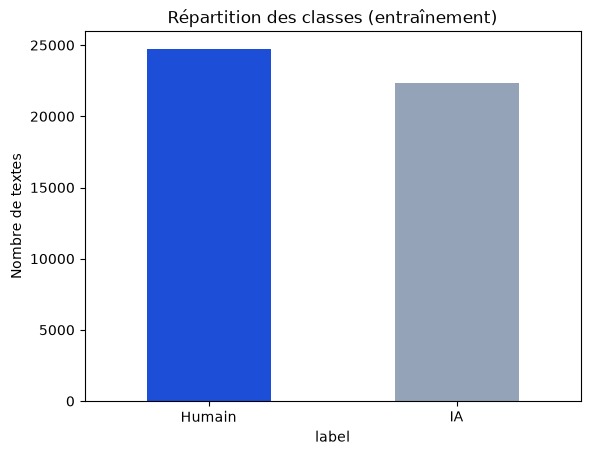

In [6]:
# Je remplace 0/1 par Humain/IA, puis je compte
train_df["label"].map(lambda i: class_names[i]).value_counts().plot(kind="bar", color=["#1d4ed8", "#94a3b8"])
plt.title("Répartition des classes (entraînement)")
plt.ylabel("Nombre de textes")
plt.xticks(rotation=0)
plt.show()

In [7]:
# J'affiche deux textes de chaque classe pour comparer leur style
for label in [0, 1]:
    for i in range(2):
        exemple = train_df[train_df["label"] == label].iloc[i]
        print("Classe :", class_names[label])
        print("Texte :", exemple["text"][:400], "...")
        print()

Classe : Humain
Texte : The drug distributors here do n't have their own armys that they can use to take over whole towns and kill people with impunity . ...

Classe : Humain
Texte : I 've been told it 's because , in the past , wealthy women were dressed by their ( right - handed ) servants , so the buttons were positioned to make it easy for them to fasten them . Wealthy men buttoned their own shirts . Not sure if it 's 100 % true , but it seems reasonable enough . ...

Classe : IA
Texte : It's important to understand that not all Russians salute Stalin and Lenin, and that many people in Russia today do not view them as heroes. Stalin and Lenin were leaders of the Soviet Union, which was a country that existed from 1922 to 1991. During their time in power, they implemented policies that resulted in the deaths of many people, including political opponents and people who were consider ...

Classe : IA
Texte : In a car with a manual transmission, the engine keeps running when the car is

En lisant ces exemples, on remarque souvent des différences de style : l'IA a tendance à utiliser des formules génériques (« this study focuses on », « in recent years », « furthermore », « overall »), alors que les humains écrivent de façon plus irrégulière, avec des détails précis, des opinions, des fautes ou des tournures familières. C'est ce genre d'indice que le modèle va apprendre à repérer.

##  Préparation du texte pour l'entraînement

Un réseau de neurones ne comprend que des nombres. J'utilise donc la couche **`TextVectorization`**, comme dans le notebook IMDB, pour :

1. **Standardiser** : tout mettre en minuscules et retirer la ponctuation
2. **Tokeniser** : découper le texte en mots
3. **Vectoriser** : remplacer chaque mot par un nombre

Ma fonction de standardisation retire aussi les éventuelles balises HTML, comme `<br />` dans les critiques IMDB.

In [8]:
def custom_standardization(input_data):
  # 1. Je mets tout en minuscules
  lowercase = tf.strings.lower(input_data, encoding="utf-8")
  # 2. Je remplace toute balise HTML (<...>) par un espace
  stripped_html = tf.strings.regex_replace(lowercase, '<[^>]+>', ' ')
  # 3. Je supprime la ponctuation
  return tf.strings.regex_replace(stripped_html,
                                  '[%s]' % re.escape(string.punctuation),
                                  '')

### Création de la couche `TextVectorization`

- **`max_tokens`** : je garde les 10 000 mots les plus fréquents ; les autres deviennent « mot inconnu »
- **`output_mode="int"`** : chaque mot est remplacé par un nombre entier
- **`output_sequence_length`** : chaque texte est ramené à 250 mots (coupé s'il est plus long, complété par des zéros s'il est plus court). Les textes les plus longs sont coupés, mais 250 mots suffisent largement pour repérer un style d'écriture.

In [9]:
max_features = 10000    # taille du vocabulaire
sequence_length = 250   # nombre de mots gardés par texte

vectorize_layer = layers.TextVectorization(
    standardize=custom_standardization,   # ma fonction de nettoyage
    max_tokens=max_features,
    output_mode='int',
    output_sequence_length=sequence_length)

J'appelle ensuite **`adapt`** : la couche lit les textes d'entraînement et construit son **dictionnaire** (chaque mot reçoit un numéro). Je le fais **uniquement sur l'entraînement**, pour que le modèle ne profite d'aucune information venant de la validation ou du test.

In [10]:
# Je garde seulement les textes (sans les étiquettes) pour construire le vocabulaire
train_text = raw_train_ds.map(lambda x, y: x)
vectorize_layer.adapt(train_text)

In [11]:
# Petite fonction qui transforme un texte en suite de nombres, en gardant son étiquette
def vectorize_text(text, label):
  text = tf.expand_dims(text, -1)   # la couche attend un lot, j'ajoute donc une dimension
  return vectorize_layer(text), label

In [12]:
# Je teste la vectorisation sur le premier texte
text_batch, label_batch = next(iter(raw_train_ds))
first_text, first_label = text_batch[0], label_batch[0]

print("Texte :", first_text)
print("Classe :", class_names[int(first_label.numpy())])
print("Texte vectorisé :", vectorize_text(first_text, first_label))

Texte : tf.Tensor(b"The drug distributors here do n't have their own armys that they can use to take over whole towns and kill people with impunity .", shape=(), dtype=string)
Classe : Humain
Texte vectorisé : (<tf.Tensor: shape=(1, 250), dtype=int64, numpy=
array([[   2,  414,    1,  214,   61,   73,   22,   34,  245,    1,    9,
          25,   20,   62,    5,  199,   90,  765, 7409,    4, 1932,   47,
          12,    1,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
 

###  Correspondance entre nombres et mots

Chaque mot a été remplacé par un nombre. Avec **`get_vocabulary()`**, je peux retrouver le mot qui correspond à un nombre donné.

In [13]:
vocab = vectorize_layer.get_vocabulary()

# Je regarde quels mots se cachent derrière deux numéros
print("1287 ---> ", vocab[1287])
print(" 313 ---> ", vocab[313])
print("Taille du vocabulaire : {}".format(len(vocab)))

1287 --->  independent
 313 --->  did
Taille du vocabulaire : 10000


Dernière étape de préparation : j'applique la vectorisation aux trois parties (entraînement, validation, test).

In [14]:
train_ds = raw_train_ds.map(vectorize_text)
val_ds = raw_val_ds.map(vectorize_text)
test_ds = raw_test_ds.map(vectorize_text)

##  Création du modèle

C'est **la même architecture** que dans le notebook IMDB. Comme le problème est aussi binaire, la dernière couche donne une seule probabilité, celle que le texte ait été **généré par une IA**.

Je fais **un seul changement** : `mask_zero=True` dans la couche Embedding. Chaque texte est complété par des zéros jusqu'à 250 mots. Sans ce réglage, `GlobalAveragePooling1D` fait la moyenne **en comptant aussi ces zéros**. Pour un texte court (par exemple 80 mots), 170 positions sur 250 sont du remplissage : la moyenne est alors dominée par le vide, et le modèle répond presque toujours la même chose. Avec `mask_zero=True`, la moyenne ne porte que sur les vrais mots.

In [15]:
embedding_dim = 16   # chaque mot sera représenté par un vecteur de 16 nombres

In [16]:
model = tf.keras.Sequential([
  # Je transforme chaque numéro de mot en vecteur de 16 nombres (appris pendant l'entraînement)
  # mask_zero=True : les zéros de remplissage sont ignorés, seuls les vrais mots comptent dans la moyenne
  layers.Embedding(max_features, embedding_dim, mask_zero=True),
  # J'éteins aléatoirement 20 % des neurones pour limiter le surapprentissage
  layers.Dropout(0.2),
  # Je fais la moyenne des vecteurs de tous les mots : un seul vecteur résume le texte
  layers.GlobalAveragePooling1D(),
  layers.Dropout(0.2),
  # Je produis une probabilité entre 0 et 1 : proche de 1 = IA, proche de 0 = humain
  layers.Dense(1, activation='sigmoid')])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Rôle de chaque couche

- **Embedding** : transforme chaque mot en vecteur. Pendant l'entraînement, les mots typiques de l'IA et les mots typiques des humains vont se retrouver dans des zones différentes de cet espace.
- **GlobalAveragePooling1D** : fait la moyenne des vecteurs du texte, ce qui donne une représentation de taille fixe quelle que soit la longueur du texte.
- **Dense (sigmoïde)** : donne la probabilité que le texte soit généré par une IA. Au-dessus de 0,5, je considère que c'est une IA.

##  Fonction de perte et optimiseur

Je garde les mêmes choix que dans le notebook IMDB, puisque c'est toujours une classification binaire :

- **Perte** : `BinaryCrossentropy`
- **Mesure suivie** : `BinaryAccuracy` avec un seuil de 0,5
- **Optimiseur** : `adam`

In [17]:
model.compile(loss=losses.BinaryCrossentropy(),
              optimizer='adam',
              metrics=[tf.metrics.BinaryAccuracy(threshold=0.5)])

##  Entraînement du modèle

Je garde 10 époques comme dans le notebook IMDB, et j'ajoute **`EarlyStopping`**, la solution recommandée à la fin de ce notebook pour éviter le surapprentissage : si la perte de validation ne s'améliore plus pendant 3 époques, l'entraînement s'arrête et le modèle revient à sa meilleure version.

In [18]:
epochs = 10   # nombre maximum de passages sur les données

# J'arrête l'entraînement si la perte de validation ne s'améliore pas pendant 3 époques,
# et je récupère les poids de la meilleure époque
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    callbacks=[early_stopping])

Epoch 1/10


c:\Users\Tania\Desktop\DEEP_LEARNING\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1472/1472 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - binary_accuracy: 0.8499 - loss: 0.4241 - val_binary_accuracy: 0.9171 - val_loss: 0.2580
Epoch 2/10
1472/1472 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - binary_accuracy: 0.9292 - loss: 0.2133 - val_binary_accuracy: 0.9461 - val_loss: 0.1722
Epoch 3/10
1472/1472 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - binary_accuracy: 0.9507 - loss: 0.1532 - val_binary_accuracy: 0.9561 - val_loss: 0.1411
Epoch 4/10
1472/1472 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - binary_accuracy: 0.9609 - loss: 0.1251 - val_binary_accuracy: 0.9588 - val_loss: 0.1276
Epoch 5/10
1472/1472 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - binary_accuracy: 0.9665 - loss: 0.1059 - val_binary_accuracy: 0.9605 - val_loss: 0.1214
Epoch 6/10
1472/1472 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - binary_accuracy: 0.9707 - loss: 0.0936 - val_binary_accuracy: 0.9621 - val_loss: 0.1186
Epoch 7/10
1472/1472 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - binary_accuracy: 0.9743 - loss: 0.0842 - val_binary_accuracy: 0.9614 - val_loss: 0.1191


##  Évaluation du modèle

J'évalue le modèle sur l'ensemble de **test**, qu'il n'a jamais vu :

- **Loss** : l'erreur du modèle (plus elle est basse, mieux c'est)
- **Accuracy** : le pourcentage de textes bien classés

In [19]:
loss, accuracy = model.evaluate(test_ds)

print("Loss : ", loss)
print("Accuracy : ", accuracy)

305/305 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - binary_accuracy: 0.9609 - loss: 0.1225
Loss :  0.1225052922964096
Accuracy :  0.9608526229858398


##  Courbes d'apprentissage

`model.fit()` garde l'historique de l'entraînement. Je l'utilise pour tracer l'évolution de la perte et de l'accuracy, sur l'entraînement et sur la validation.

In [20]:
# Je récupère l'historique sous forme de dictionnaire
history_dict = history.history
history_dict.keys()

dict_keys(['binary_accuracy', 'loss', 'val_binary_accuracy', 'val_loss'])

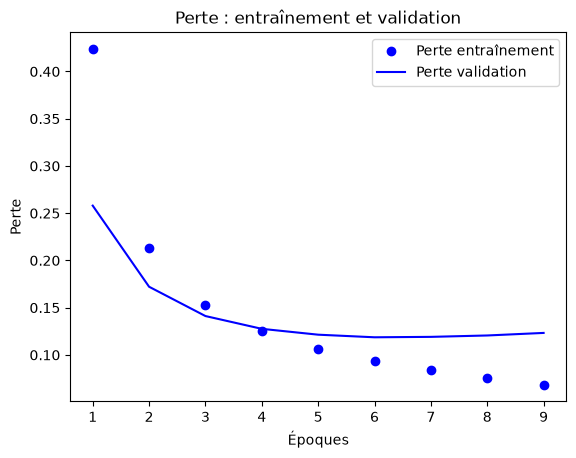

In [21]:
acc = history_dict['binary_accuracy']
val_acc = history_dict['val_binary_accuracy']
loss = history_dict['loss']
val_loss = history_dict['val_loss']

epochs = range(1, len(acc) + 1)

# Points bleus : perte sur l'entraînement
plt.plot(epochs, loss, 'bo', label='Perte entraînement')
# Ligne bleue : perte sur la validation
plt.plot(epochs, val_loss, 'b', label='Perte validation')
plt.title('Perte : entraînement et validation')
plt.xlabel('Époques')
plt.ylabel('Perte')
plt.legend()

plt.show()

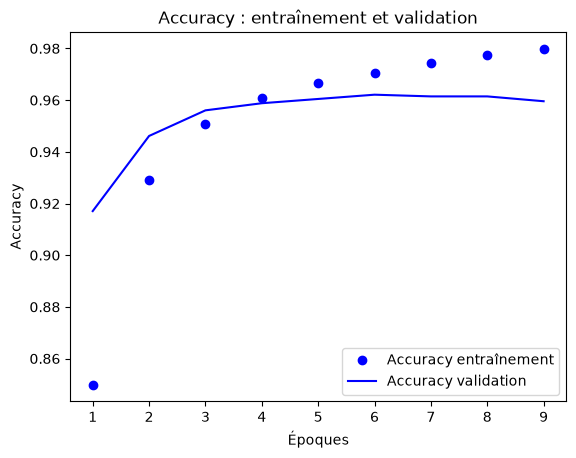

In [22]:
# Même graphique, cette fois pour l'accuracy
plt.plot(epochs, acc, 'bo', label='Accuracy entraînement')
plt.plot(epochs, val_acc, 'b', label='Accuracy validation')
plt.title('Accuracy : entraînement et validation')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

plt.show()

**Comment lire ces courbes :** si la courbe d'entraînement continue de s'améliorer alors que celle de validation stagne ou se dégrade, le modèle apprend les textes par cœur au lieu de généraliser. C'est le **surapprentissage**, et c'est ce que `EarlyStopping` limite.

##  Analyse détaillée des erreurs

L'accuracy globale ne dit pas **quel type d'erreur** fait le modèle. Or les deux erreurs n'ont pas les mêmes conséquences :

- **Faux positif** : accuser un chercheur d'avoir utilisé une IA alors qu'il a écrit lui-même. C'est l'erreur la plus grave.
- **Faux négatif** : laisser passer un texte généré par IA.

La **matrice de confusion** montre combien de fois chaque erreur se produit.

305/305 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
              precision    recall  f1-score   support

      Humain       0.98      0.95      0.96      5346
          IA       0.94      0.98      0.96      4412

    accuracy                           0.96      9758
   macro avg       0.96      0.96      0.96      9758
weighted avg       0.96      0.96      0.96      9758



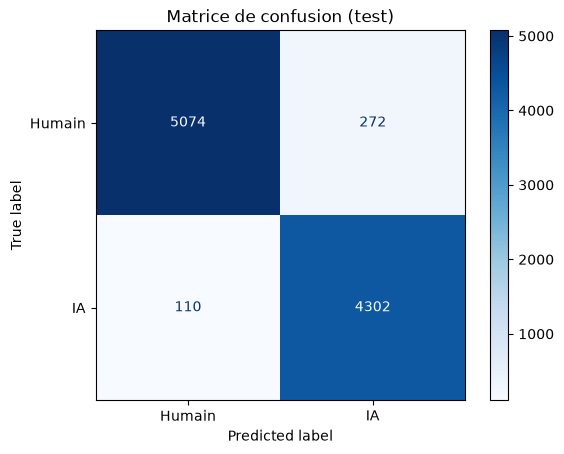

In [23]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Les vraies classes des textes de test
y_true = np.concatenate([y.numpy() for _, y in test_ds])
# Les classes prédites : au-dessus de 0,5 = IA (1), sinon humain (0)
y_pred = (model.predict(test_ds).ravel() > 0.5).astype(int)

# Rapport détaillé par classe : précision, rappel, F1
print(classification_report(y_true, y_pred, target_names=class_names))

# Matrice de confusion : lignes = vraie classe, colonnes = classe prédite
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap='Blues')
plt.title("Matrice de confusion (test)")
plt.show()

##  Les mots qui trahissent l'IA

Mon modèle est simple : il fait la **moyenne** des vecteurs des mots, puis la couche Dense calcule un score. Grâce à cette simplicité, je peux calculer **l'influence de chaque mot** sur la décision :

> score d'un mot = (vecteur du mot) × (poids de la couche Dense)

- Un score **positif** pousse le modèle vers « IA »
- Un score **négatif** pousse le modèle vers « Humain »

C'est une façon d'**ouvrir la boîte noire** et de vérifier que le modèle a appris des indices qui ont du sens.

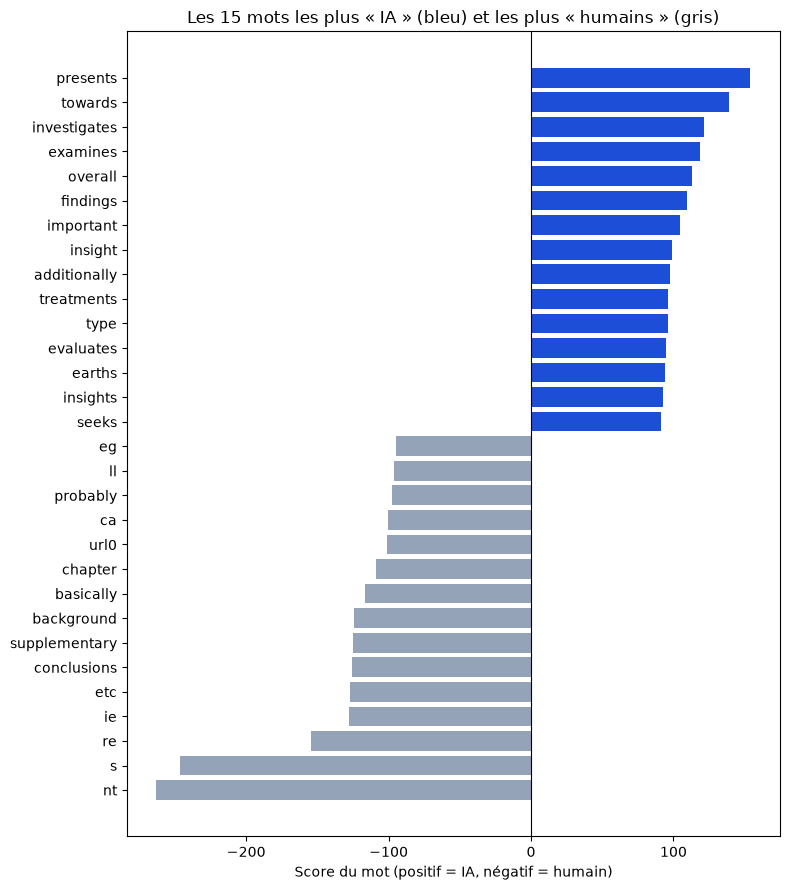

In [24]:
# Je récupère ce que le modèle a appris
embeddings = model.layers[0].get_weights()[0]        # un vecteur de 16 nombres par mot
dense_weights = model.layers[-1].get_weights()[0]    # les 16 poids de la dernière couche

# Je calcule le score de chaque mot du vocabulaire
word_scores = (embeddings @ dense_weights).ravel()
vocab = np.array(vectorize_layer.get_vocabulary())

# Je classe les mots du plus "humain" au plus "IA"
# (je saute les 2 premiers éléments du vocabulaire : le remplissage et le mot inconnu)
order = np.argsort(word_scores[2:]) + 2
mots_humains = order[:15]
mots_ia = order[-15:]

# Graphique : en bleu les mots qui poussent vers IA, en gris ceux qui poussent vers Humain
selection = np.concatenate([mots_humains, mots_ia])
couleurs = ["#94a3b8"] * 15 + ["#1d4ed8"] * 15
plt.figure(figsize=(8, 9))
plt.barh(vocab[selection], word_scores[selection], color=couleurs)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Les 15 mots les plus « IA » (bleu) et les plus « humains » (gris)")
plt.xlabel("Score du mot (positif = IA, négatif = humain)")
plt.tight_layout()
plt.show()

Je m'attends à trouver côté IA des mots génériques et des formules de transition, et côté humain des termes techniques, des unités, des chiffres ou des mots propres à une discipline. Si c'est le cas, le modèle a appris une vraie différence de **style d'écriture**.

##  Export du modèle

Jusqu'ici, la vectorisation était faite **avant** le modèle. Pour pouvoir donner directement du **texte brut** au modèle (ce dont l'interface aura besoin), je place la couche `TextVectorization` **à l'intérieur** d'un nouveau modèle.

 **Correction par rapport au notebook IMDB.** Celui-ci ajoutait `layers.Activation('sigmoid')` après un modèle qui avait **déjà** une sigmoïde. La sigmoïde était donc appliquée deux fois, ce qui faisait chuter l'accuracy à **0,50** à l'export alors que le modèle atteignait 0,89. Ici, je n'ajoute **aucune activation**.

In [25]:
# Nouveau modèle = vectorisation + modèle entraîné
export_model = tf.keras.Sequential([
  vectorize_layer,
  model
])

export_model.compile(
    loss=losses.BinaryCrossentropy(from_logits=False), optimizer="adam", metrics=['accuracy']
)

# Je vérifie sur raw_test_ds (texte brut) : je dois retrouver la même accuracy qu'avant
metrics = export_model.evaluate(raw_test_ds, return_dict=True)
print(metrics)

305/305 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9609 - loss: 0.1225
{'accuracy': 0.9608526229858398, 'loss': 0.1225052922964096}


##  Stress test : jusqu'où mon modèle est-il fiable ?

Une très bonne accuracy sur le test ne veut pas dire que le modèle marche partout. Les textes du test viennent des mêmes sources que ceux de l'entraînement : mêmes domaines, mêmes IA génératrices.

Les études récentes sur les détecteurs de texte IA montrent qu'ils **perdent beaucoup en fiabilité** dès que le texte vient d'une autre IA, d'un autre domaine, ou qu'il a été retouché par un humain. Je teste donc mon modèle dans des situations de plus en plus difficiles.

Je commence par une petite fonction qui analyse un texte et affiche le verdict.

In [26]:
def analyser(texte):
    # Le modèle exporté prend directement du texte brut
    proba_ia = float(export_model.predict(tf.constant([texte]), verbose=0)[0][0])
    verdict = "IA" if proba_ia > 0.5 else "Humain"
    print(f"Verdict : {verdict}  (probabilité IA = {proba_ia:.1%})")
    return proba_ia

**Niveau 1 : des textes du jeu de test.** Le modèle devrait avoir raison.

In [27]:
humain_test = test_df[test_df["label"] == 0].iloc[0]["text"]
ia_test = test_df[test_df["label"] == 1].iloc[0]["text"]

print("Texte réellement écrit par un humain :")
analyser(humain_test)
print()
print("Texte réellement généré par une IA :")
analyser(ia_test)

Texte réellement écrit par un humain :
Verdict : Humain  (probabilité IA = 0.1%)

Texte réellement généré par une IA :
Verdict : IA  (probabilité IA = 99.5%)


0.995353639125824

**Niveau 2 : un texte généré aujourd'hui par une IA récente.** Je demande à ChatGPT (ou une autre IA) : *« Write a scientific abstract for a paper titled ... »*, puis je colle le résultat ci-dessous. Le texte déjà présent a été généré par un assistant IA pour servir d'exemple ; pendant la présentation, je le remplace par un texte généré en direct.

In [28]:
texte_ia_recent = """Malaria remains a leading cause of morbidity and mortality in sub-Saharan Africa, \
particularly among children under five. In this study, we investigate the potential of low-cost mobile \
technologies to improve early diagnosis in rural communities. We developed a smartphone-based screening \
tool and evaluated it across several health centers. Our findings demonstrate that the proposed approach \
significantly enhances diagnostic accuracy while reducing time to treatment. Furthermore, the tool was well \
accepted by community health workers. Overall, these results highlight the promising role of mobile health \
solutions in strengthening healthcare systems in resource-limited settings."""

analyser(texte_ia_recent)

Verdict : IA  (probabilité IA = 99.2%)


0.9918229579925537

**Niveau 3 : le même texte, reformulé par un humain.** Je réécris le texte précédent avec mes propres mots : je supprime les formules génériques (« furthermore », « overall », « highlight the promising role »), j'ajoute des détails concrets. Est-ce que le modèle se fait piéger ? (Les chiffres de cet exemple sont fictifs.)

In [29]:
texte_reformule = """We tested a smartphone malaria screening app in 12 rural health centres in the \
Boucle du Mouhoun region between June and October. Nurses photographed 1,840 blood smears; the app \
flagged 412 as positive, against 397 confirmed by microscopy (sensitivity 91%, specificity 96%). \
Median time from consultation to treatment fell from 2.5 days to 4 hours. Battery life and poor \
lighting were the two main problems reported by staff."""

analyser(texte_reformule)

Verdict : Humain  (probabilité IA = 0.0%)


3.794255098910071e-05

**Niveau 4 : un message très court de la vie quotidienne.** Mon modèle a surtout vu des textes de plusieurs phrases. Que fait-il face à un message de quelques mots ?

In [30]:
texte_hors_domaine = "Hey, are we still meeting tomorrow at 10? I'll bring the slides and the snacks."

analyser(texte_hors_domaine)

Verdict : Humain  (probabilité IA = 0.3%)


0.003069167258217931

### Ce que m'apprend le stress test

- Sur des textes **semblables à l'entraînement**, le modèle est très fiable.
- Face à une **IA plus récente**, à un texte **reformulé** ou **hors domaine**, le résultat devient moins sûr. Le modèle s'appuie surtout sur le **vocabulaire** ; un humain qui écrit de façon générique, ou une IA qui écrit de façon précise, peut le tromper.
- Conclusion : un tel détecteur peut servir d'**outil d'alerte**, mais **jamais de preuve** pour accuser quelqu'un. C'est d'ailleurs le cas de tous les détecteurs actuels, même commerciaux.

##  Interface utilisateur

Pour que n'importe qui puisse utiliser le modèle sans lire de code, je crée une interface web avec **Gradio**. L'utilisateur colle un texte, clique sur « Analyser », et obtient :

- le **verdict** (Humain ou IA) et le **niveau de confiance**
- le texte avec les **mots surlignés** qui ont le plus influencé la décision (grâce aux scores calculés plus haut)

In [31]:
import gradio as gr
import html

# Dictionnaire mot -> score, pour retrouver rapidement l'influence de chaque mot
score_par_mot = {mot: float(score) for mot, score in zip(vocab, word_scores)}
# Je ne surligne que les mots vraiment influents : les 10 % de scores les plus forts
seuil = float(np.quantile(np.abs(word_scores[2:]), 0.90))

def nettoyer_mot(mot):
    # Même nettoyage que custom_standardization, mais pour un seul mot
    return mot.lower().translate(str.maketrans("", "", string.punctuation))

def surligner(texte):
    # Je découpe le texte en mots et je donne une étiquette aux mots influents
    morceaux = []
    for mot in texte.split():
        score = score_par_mot.get(nettoyer_mot(mot), 0.0)
        if score > seuil:
            morceaux.append((mot + " ", "Indice IA"))
        elif score < -seuil:
            morceaux.append((mot + " ", "Indice humain"))
        else:
            morceaux.append((mot + " ", None))
    return morceaux

def carte_resultat(proba_ia, nb_mots):
    # Je construis la carte qui affiche le verdict
    est_ia = proba_ia > 0.5
    verdict = "Probablement généré par une IA" if est_ia else "Probablement écrit par un humain"
    confiance = proba_ia if est_ia else 1 - proba_ia
    couleur = "#1d4ed8" if est_ia else "#475569"
    avertissement = ""
    if nb_mots < 50:
        avertissement = "<p class='note'>Texte court : le résultat est moins fiable en dessous de 50 mots.</p>"
    return f"""
    <div class='carte'>
      <div class='etiquette'>Résultat de l'analyse</div>
      <div class='verdict' style='color:{couleur}'>{verdict}</div>
      <div class='barre'><div class='remplissage' style='width:{proba_ia*100:.0f}%'></div></div>
      <div class='legende'><span>Humain</span><span>Probabilité IA : <b>{proba_ia:.0%}</b></span><span>IA</span></div>
      <div class='confiance'>Confiance du modèle : <b>{confiance:.0%}</b> · {nb_mots} mots analysés</div>
      {avertissement}
    </div>"""

def analyser_interface(texte):
    # Fonction appelée quand l'utilisateur clique sur "Analyser"
    if not texte or not texte.strip():
        return "<div class='carte'><div class='etiquette'>Collez un texte pour lancer l'analyse.</div></div>", []
    proba_ia = float(export_model.predict(tf.constant([texte]), verbose=0)[0][0])
    return carte_resultat(proba_ia, len(texte.split())), surligner(texte)

Je définis maintenant l'apparence : une palette sobre (bleu et gris), une police lisible, et une mise en page en deux colonnes, avec le texte à gauche et le résultat à droite.

In [32]:
# Style de l'interface : sobre et professionnel
theme = gr.themes.Base(
    primary_hue="blue",
    neutral_hue="slate",
    font=[gr.themes.GoogleFont("Inter"), "sans-serif"],
)

css = """
.gradio-container {max-width: 1100px !important; margin: auto;}
#entete h1 {font-size: 1.7rem; font-weight: 700; margin-bottom: 0;}
#entete p {color: var(--body-text-color-subdued); margin-top: 4px;}
.carte {border: 1px solid var(--border-color-primary); border-radius: 12px; padding: 20px;
        background: var(--block-background-fill);}
.etiquette {font-size: 0.8rem; text-transform: uppercase; letter-spacing: 0.06em;
            color: var(--body-text-color-subdued);}
.verdict {font-size: 1.4rem; font-weight: 700; margin: 8px 0 16px;}
.barre {height: 10px; border-radius: 5px; background: #e2e8f0; overflow: hidden;}
.remplissage {height: 100%; background: linear-gradient(90deg, #94a3b8, #1d4ed8);}
.legende {display: flex; justify-content: space-between; font-size: 0.85rem; margin-top: 6px;
          color: var(--body-text-color-subdued);}
.confiance {margin-top: 14px; font-size: 0.95rem;}
.note {margin-top: 10px; font-size: 0.85rem; color: #b45309;}
#pied {font-size: 0.8rem; color: var(--body-text-color-subdued); text-align: center;}
"""

with gr.Blocks(title="Détecteur de texte IA") as interface:
    # En-tête
    gr.Markdown(
        "# Détecteur de texte généré par IA\n"
        "Collez un texte en anglais (au moins 50 mots). Le modèle estime s'il a été écrit par un humain ou généré par une IA.",
        elem_id="entete")

    with gr.Row():
        # Colonne de gauche : saisie du texte
        with gr.Column(scale=3):
            entree = gr.Textbox(label="Texte à analyser", lines=12,
                                placeholder="Collez ici un texte en anglais...")
            with gr.Row():
                bouton_effacer = gr.ClearButton(value="Effacer")
                bouton = gr.Button("Analyser", variant="primary")
        # Colonne de droite : résultat
        with gr.Column(scale=2):
            resultat = gr.HTML("<div class='carte'><div class='etiquette'>Le résultat apparaîtra ici.</div></div>")

    # Texte surligné : les mots qui ont le plus influencé la décision
    mots = gr.HighlightedText(label="Mots les plus influents",
                              color_map={"Indice IA": "#93c5fd", "Indice humain": "#bbf7d0"},
                              show_legend=True)

    # Exemples prêts à l'emploi, tirés du jeu de test
    gr.Examples(examples=[[humain_test], [ia_test], [texte_reformule]],
                inputs=entree, label="Exemples")

    gr.Markdown("Modèle entraîné from scratch (Embedding + GlobalAveragePooling1D + Dense) sur environ "
                "80 000 textes humains et générés par plusieurs IA. Outil d'aide à la décision : un résultat ne constitue jamais une preuve.",
                elem_id="pied")

    # Ce qui se passe quand on clique
    bouton.click(analyser_interface, inputs=entree, outputs=[resultat, mots])
    bouton_effacer.add([entree, mots])

Je lance l'interface **dans le navigateur**, dans un onglet à part, plutôt qu'à l'intérieur du notebook :

- `inbrowser=True` : Gradio ouvre automatiquement un nouvel onglet dans le navigateur
- `inline=False` : l'interface ne s'affiche pas en plus dans le notebook
- L'adresse est aussi affichée sous la cellule (en général `http://127.0.0.1:7860`) : si l'onglet ne s'ouvre pas tout seul, il suffit de cliquer dessus

L'interface reste active tant que le notebook tourne. Pour l'arrêter, j'exécute `interface.close()`.

In [33]:
# Je ferme une éventuelle interface déjà ouverte (utile si je relance la cellule)
try:
    interface.close()
except Exception:
    pass

# Je lance l'interface avec le thème et le style définis plus haut, dans un onglet du navigateur.
# Avec share=True, Gradio crée en plus un lien public temporaire
# (pratique pour la montrer depuis un autre appareil, ou si j'utilise Google Colab)
interface.launch(inbrowser=True, inline=False, share=False, theme=theme, css=css)

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


##  Pistes d'amélioration

- **Encore plus de données** : ajouter des textes en français et des textes générés par les toutes dernières IA, pour suivre leur évolution
- **Tenir compte de l'ordre des mots** : la moyenne des embeddings ignore l'ordre ; un LSTM ou un petit Transformer entraîné from scratch pourrait capter des structures de phrase
- **Indices de style** : longueur des phrases, diversité du vocabulaire, ponctuation, ajoutés comme entrées supplémentaires
- **Seuil adapté** : relever le seuil au-dessus de 0,5 pour réduire les faux positifs, c'est-à-dire éviter d'accuser à tort un auteur humain

##  Conclusion

J'ai repris le modèle de classification binaire du notebook IMDB et je l'ai appliqué à un problème actuel : **distinguer un texte écrit par un humain d'un texte généré par une IA**. Le modèle est entièrement construit et entraîné par moi, sans modèle pré-entraîné.

Au-delà du score, le projet montre **ce que le modèle a appris** (les mots qui trahissent l'IA), **où il échoue** (stress test) et propose une **interface** utilisable par tout le monde. Il rappelle aussi une limite importante : ce type de détecteur est un outil d'alerte, pas une preuve.